# DNA Methylation Prediction

## Project Overview
This project aims to analyze genomic features and develop 
machine learning models to predict DNA methylation status.

## Objectives
- Understand and explore the genomic dataset.
- Perform data cleaning and preprocessing.
- Conduct exploratory data analysis (EDA).
- Identify relationships between genomic features.
- Build and evaluate machine learning classification models.
- Interpret model performance and identify important features.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
full_data = pd.read_csv(r"C:\Users\saksh\Downloads\DNA methylation Dataset\full_dataset.csv")
test_data = pd.read_csv(r"C:\Users\saksh\Downloads\DNA methylation Dataset\test_data.csv")
train_data = pd.read_csv(r"C:\Users\saksh\Downloads\DNA methylation Dataset\train_data.csv")

In [4]:
full_data.shape

(1000, 5)

In [5]:
test_data.shape

(200, 5)

In [6]:
train_data.shape

(800, 5)

In [7]:
full_data.head()

,cpg_density,genomic_location,regulatory_score,conservation_score,methylation_status
0,0.799343,0.949839,0.297447,0.268438,1
1,0.672347,0.831158,0.456644,0.477923,1
2,0.829538,0.614908,0.262274,0.567279,0
3,1.000000,0.438266,0.407612,1.000000,1
4,0.653169,0.774556,0.000000,0.761311,0


In [8]:
train_data.head()

,cpg_density,genomic_location,regulatory_score,conservation_score,methylation_status
0,0.814178,0.289034,0.124878,0.886699,0
1,0.739617,0.348364,0.551552,0.682098,0
2,0.587255,0.642604,0.301904,1.000000,1
3,0.524876,0.856016,0.737112,0.613370,1
4,0.554851,0.659592,0.411018,0.613699,0


In [9]:
test_data.head()

,cpg_density,genomic_location,regulatory_score,conservation_score,methylation_status
0,0.988255,0.872828,0.604303,0.606866,1
1,0.722185,0.709081,0.555155,0.572296,1
2,0.935888,0.508670,0.474969,1.000000,1
3,0.817663,0.726998,0.424538,0.607667,1
4,0.725621,0.748389,0.000000,0.570561,0


In [10]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cpg_density         800 non-null    float64
 1   genomic_location    800 non-null    float64
 2   regulatory_score    800 non-null    float64
 3   conservation_score  800 non-null    float64
 4   methylation_status  800 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 31.4 KB


In [11]:
train_data.describe()

,cpg_density,genomic_location,regulatory_score,conservation_score,methylation_status
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,0.698849,0.611934,0.499922,0.644797,0.553750
std,0.182598,0.235474,0.266550,0.203822,0.497414
min,0.051747,0.000000,0.000000,0.064110,0.000000
25%,0.570434,0.447481,0.312028,0.501473,0.000000
50%,0.701784,0.614580,0.500735,0.656847,1.000000
75%,0.830100,0.782221,0.695370,0.792637,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000


In [12]:
train_data.isnull().sum()

cpg_density           0
genomic_location      0
regulatory_score      0
conservation_score    0
methylation_status    0
dtype: int64

In [13]:
(train_data.isnull().sum() / len(train_data)) * 100

cpg_density           0.0
genomic_location      0.0
regulatory_score      0.0
conservation_score    0.0
methylation_status    0.0
dtype: float64

In [15]:
train_data.duplicated().sum()

np.int64(0)

In [18]:
for column in train_data.columns:
    print(f"{column}: {train_data[column].nunique()} unique values")

cpg_density: 737 unique values
genomic_location: 737 unique values
regulatory_score: 736 unique values
conservation_score: 764 unique values
methylation_status: 2 unique values


In [19]:
print(train_data['methylation_status'].value_counts())

methylation_status
1    443
0    357
Name: count, dtype: int64


In [20]:
print(train_data['methylation_status'].value_counts(normalize=True) * 100)

methylation_status
1    55.375
0    44.625
Name: proportion, dtype: float64


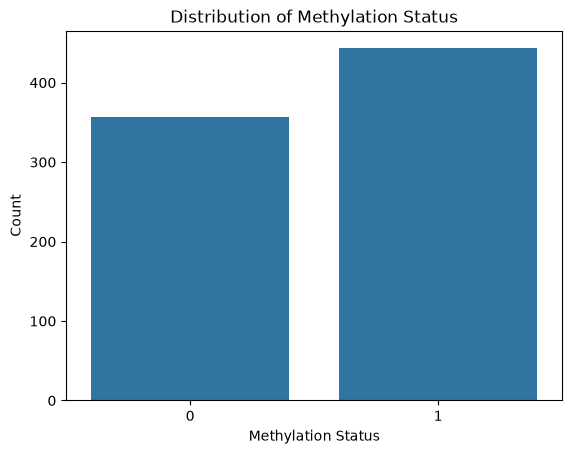

In [21]:
sns.countplot(data=train_data, x='methylation_status')

plt.title('Distribution of Methylation Status')
plt.xlabel('Methylation Status')
plt.ylabel('Count')

plt.show()

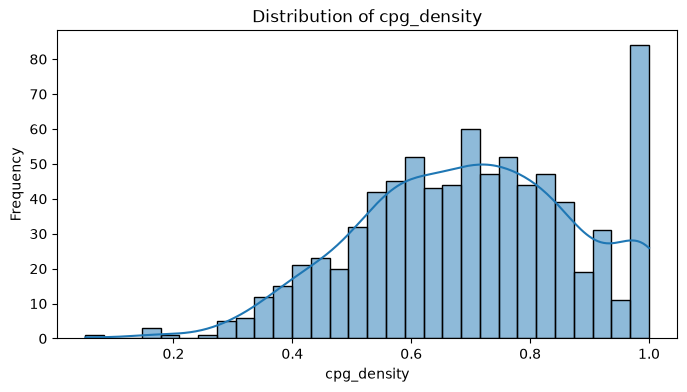

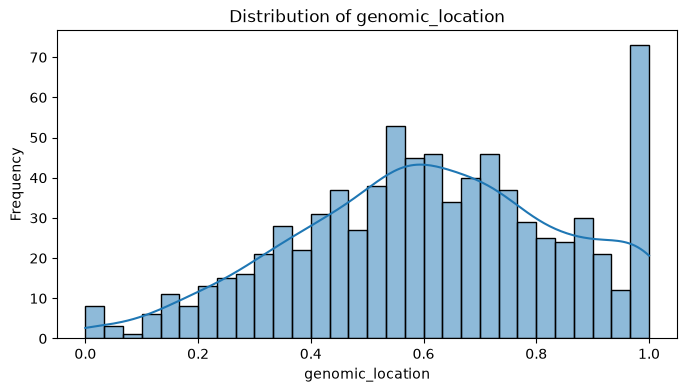

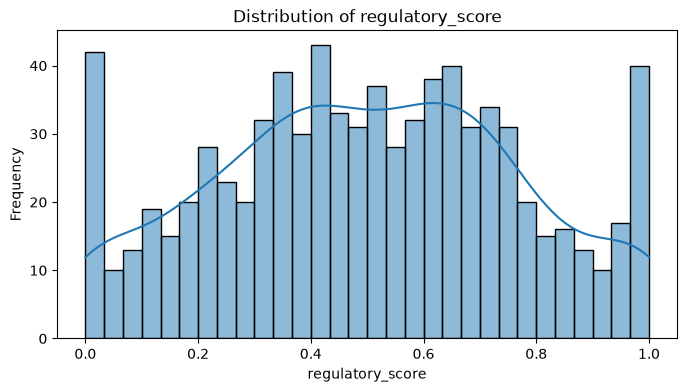

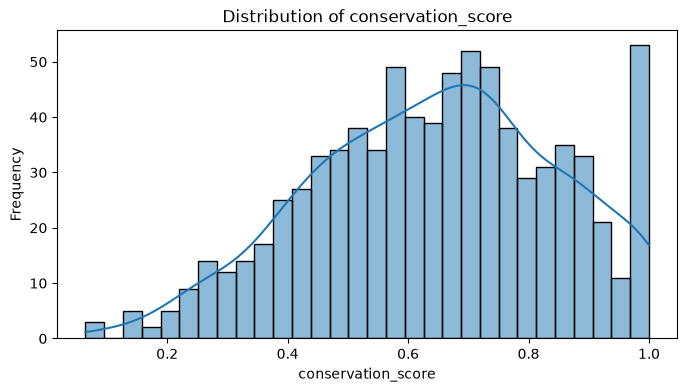

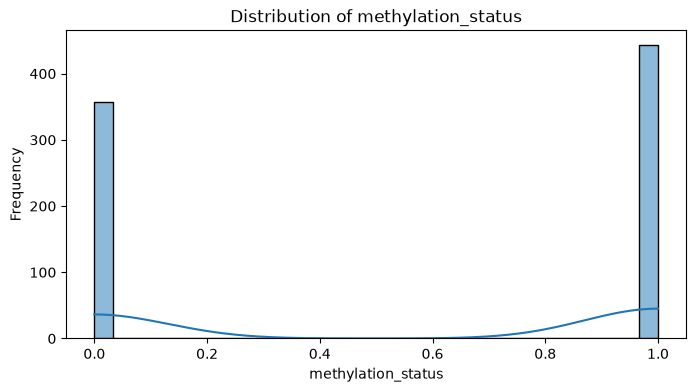

In [22]:
# Select numerical features
numerical_features = train_data.select_dtypes(include=np.number).columns

# Plot distribution of each numerical feature
for column in numerical_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=train_data,
        x=column,
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

    plt.show()

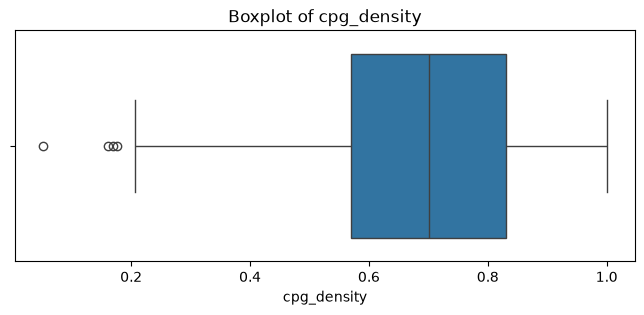

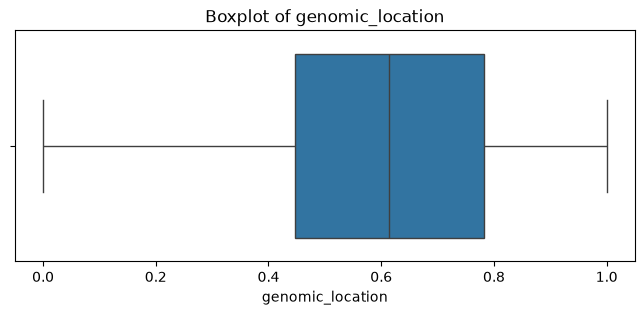

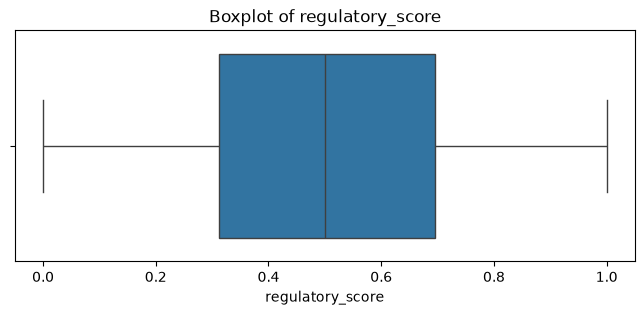

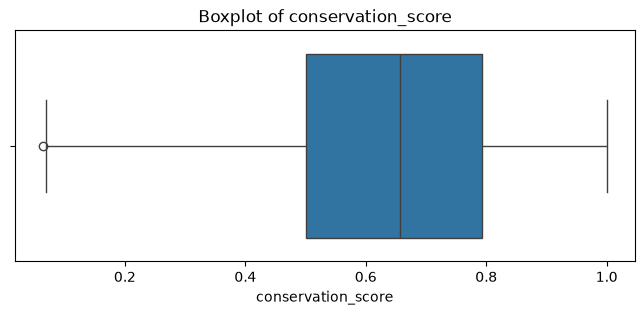

In [23]:
# Exclude target variable
features = train_data.drop(columns=['methylation_status'])

for column in features.columns:
    plt.figure(figsize=(8, 3))

    sns.boxplot(x=train_data[column])

    plt.title(f'Boxplot of {column}')
    plt.xlabel(column)

    plt.show()

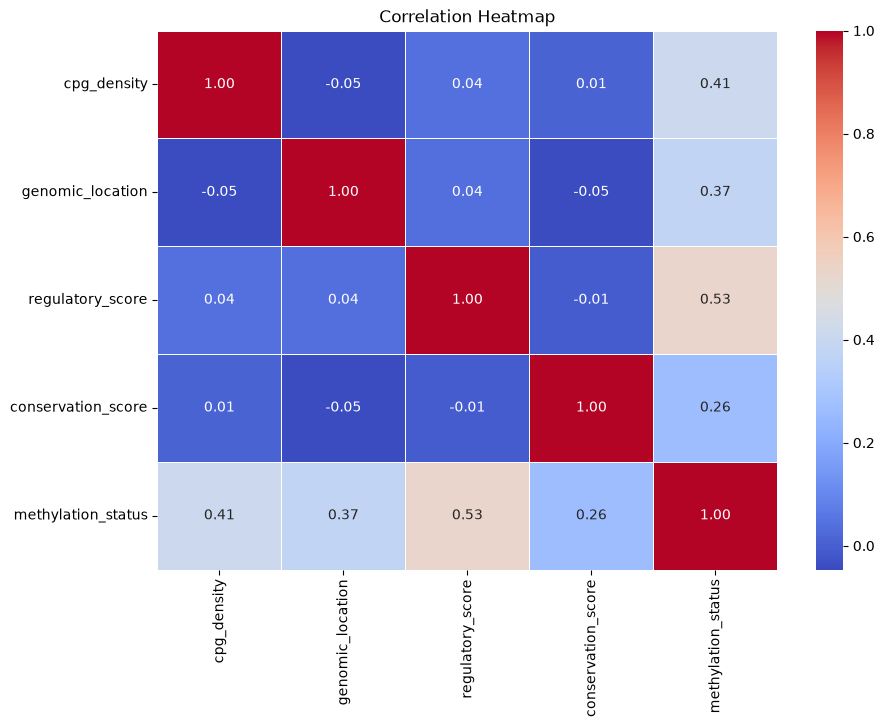

In [24]:
# Calculate correlation matrix
correlation_matrix = train_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()

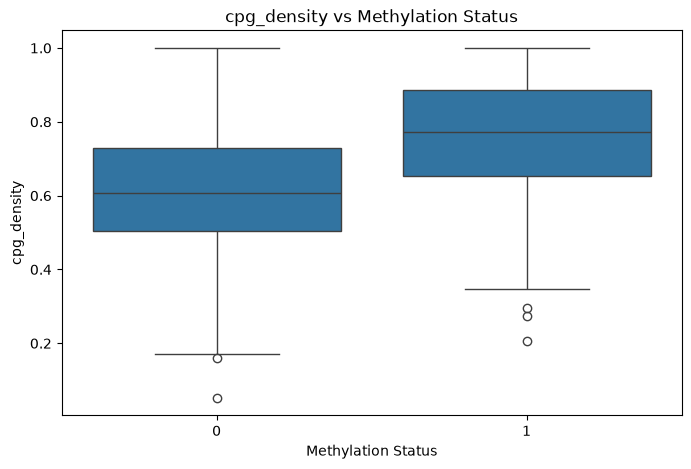

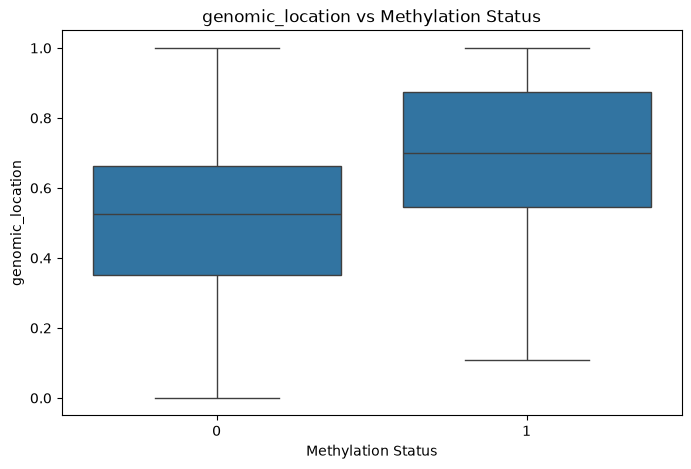

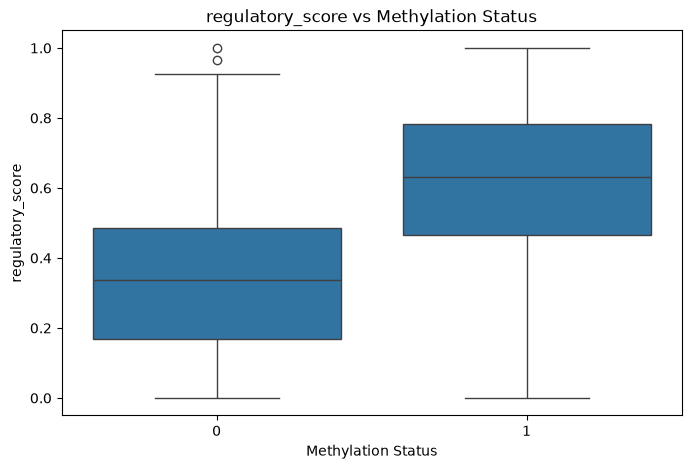

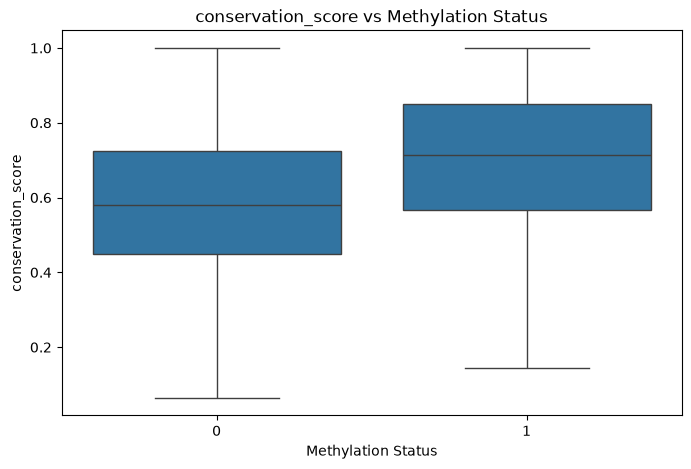

In [25]:
for column in features.columns:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train_data,
        x='methylation_status',
        y=column
    )

    plt.title(f'{column} vs Methylation Status')
    plt.xlabel('Methylation Status')
    plt.ylabel(column)

    plt.show()

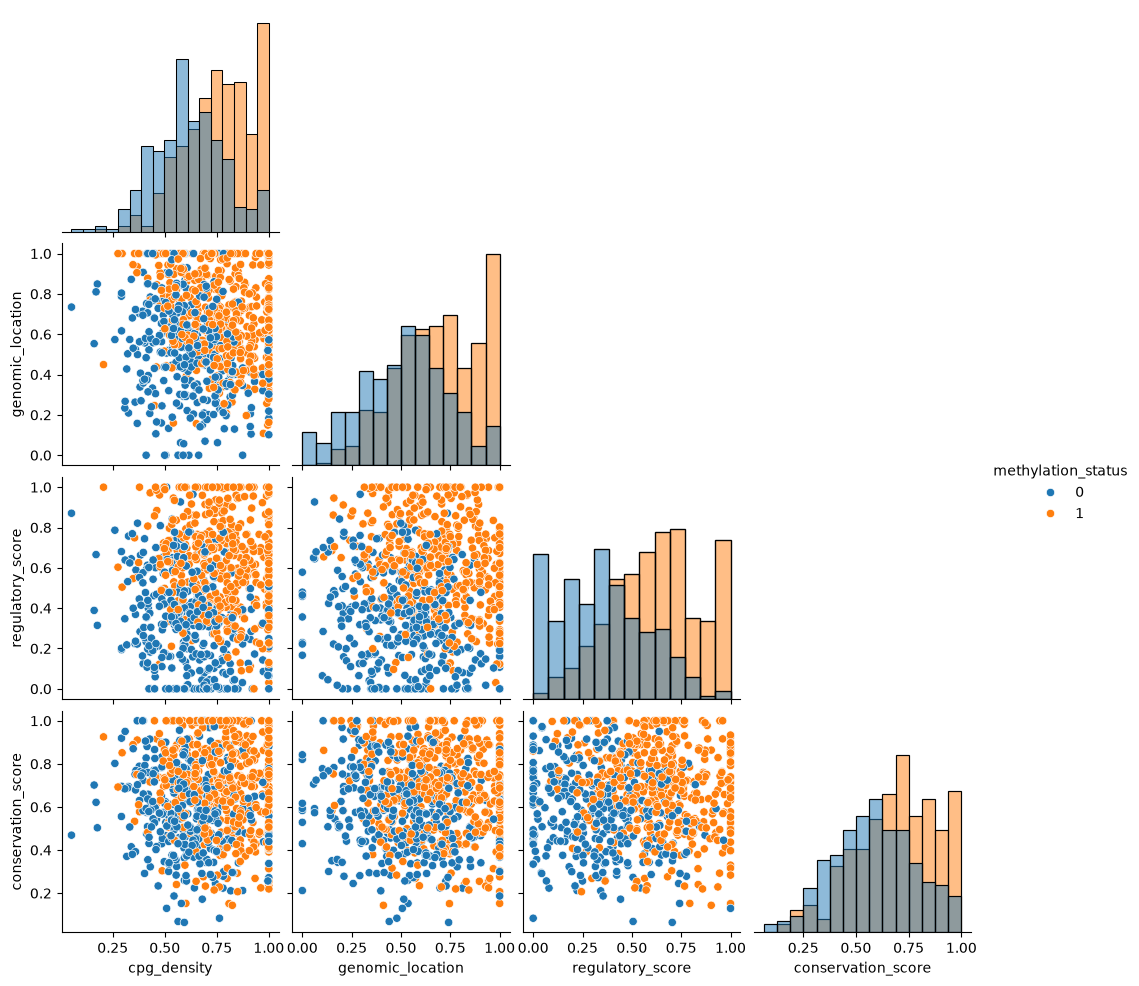

In [26]:
sns.pairplot(
    train_data,
    hue='methylation_status',
    diag_kind='hist',
    corner=True
)

plt.show()

In [30]:
x_train = train_data.drop('methylation_status', axis=1)
y_train = train_data['methylation_status']

x_test = test_data.drop('methylation_status', axis=1)
y_test = test_data['methylation_status']

In [33]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(800, 4)
(200, 4)
(800,)
(200,)


In [36]:
from sklearn.linear_model import LogisticRegression 
lr_model = LogisticRegression()
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [40]:
print(accuracy_score(y_test, lr_pred))
print(precision_score(y_test, lr_pred))
print(recall_score(y_test, lr_pred))
print(f1_score(y_test, lr_pred))
print(confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred))

0.975
0.9649122807017544
0.990990990990991
0.9777777777777777
[[ 85   4]
 [  1 110]]
              precision    recall  f1-score   support

           0       0.99      0.96      0.97        89
           1       0.96      0.99      0.98       111

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200



In [42]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train)
dt_pred = dt_model.predict(x_test)

In [43]:
print(accuracy_score(y_test, dt_pred))
print(precision_score(y_test, dt_pred))
print(recall_score(y_test, dt_pred))
print(f1_score(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred))

0.87
0.8761061946902655
0.8918918918918919
0.8839285714285714
[[75 14]
 [12 99]]
              precision    recall  f1-score   support

           0       0.86      0.84      0.85        89
           1       0.88      0.89      0.88       111

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



In [45]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=200,random_state=42)
rf_model.fit(x_train, y_train)
rf_pred = rf_model.predict(x_test)

In [46]:
print(accuracy_score(y_test, rf_pred))
print(precision_score(y_test, rf_pred))
print(recall_score(y_test, rf_pred))
print(f1_score(y_test, rf_pred))
print(confusion_matrix(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

0.935
0.9454545454545454
0.9369369369369369
0.9411764705882353
[[ 83   6]
 [  7 104]]
              precision    recall  f1-score   support

           0       0.92      0.93      0.93        89
           1       0.95      0.94      0.94       111

    accuracy                           0.94       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.94      0.94      0.94       200



In [47]:
from sklearn.model_selection import GridSearchCV

In [48]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

In [50]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)
grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [None, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], 'n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_

In [51]:
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Best Cross Validation Score: 0.9284098796405024


In [53]:
best_rf_model = RandomForestClassifier( n_estimators=300,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=1,
    random_state=42
)
best_rf_model.fit(x_train, y_train)
best_rf_pred = best_rf_model.predict(x_test)

In [54]:
print(accuracy_score(y_test, best_rf_pred))
print(precision_score(y_test, best_rf_pred))
print(recall_score(y_test, best_rf_pred))
print(f1_score(y_test, best_rf_pred))
print(confusion_matrix(y_test, best_rf_pred))
print(classification_report(y_test, best_rf_pred))

0.935
0.9454545454545454
0.9369369369369369
0.9411764705882353
[[ 83   6]
 [  7 104]]
              precision    recall  f1-score   support

           0       0.92      0.93      0.93        89
           1       0.95      0.94      0.94       111

    accuracy                           0.94       200
   macro avg       0.93      0.93      0.93       200
weighted avg       0.94      0.94      0.94       200



In [56]:
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importance': best_rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

              Feature  Importance
2    regulatory_score    0.364592
0         cpg_density    0.257769
1    genomic_location    0.240414
3  conservation_score    0.137224


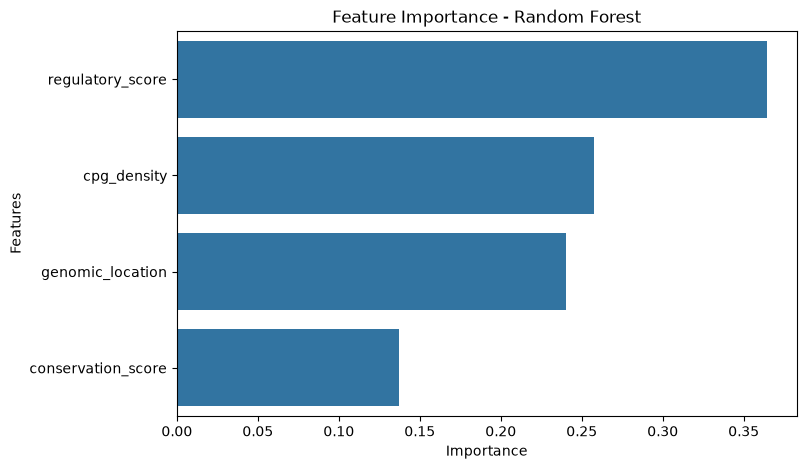

In [57]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Features')

plt.show()

In [58]:
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, best_rf_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, best_rf_pred)
    ],
    'Recall': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, best_rf_pred)
    ],
    'F1 Score': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, best_rf_pred)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.975,0.964912,0.990991,0.977778
1,Decision Tree,0.870,0.876106,0.891892,0.883929
2,Random Forest,0.935,0.945455,0.936937,0.941176
3,Tuned Random Forest,0.935,0.945455,0.936937,0.941176


In [60]:
from sklearn.model_selection import cross_val_score

lr_cv_scores = cross_val_score(
    LogisticRegression(),
    x_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", lr_cv_scores)
print("Average CV Accuracy:", lr_cv_scores.mean())
print("Standard Deviation:", lr_cv_scores.std())

Cross Validation Scores: [0.9875  0.975   0.98125 0.95    0.96875]
Average CV Accuracy: 0.9724999999999999
Standard Deviation: 0.01286953767623377


In [62]:
lr_coefficients = pd.DataFrame({'Feature': x_train.columns,'Coefficient': lr_model.coef_[0]})
lr_coefficients = lr_coefficients.sort_values(by='Coefficient',ascending=False)
print(lr_coefficients)

              Feature  Coefficient
0         cpg_density     6.712933
2    regulatory_score     6.327850
1    genomic_location     5.581972
3  conservation_score     4.393845


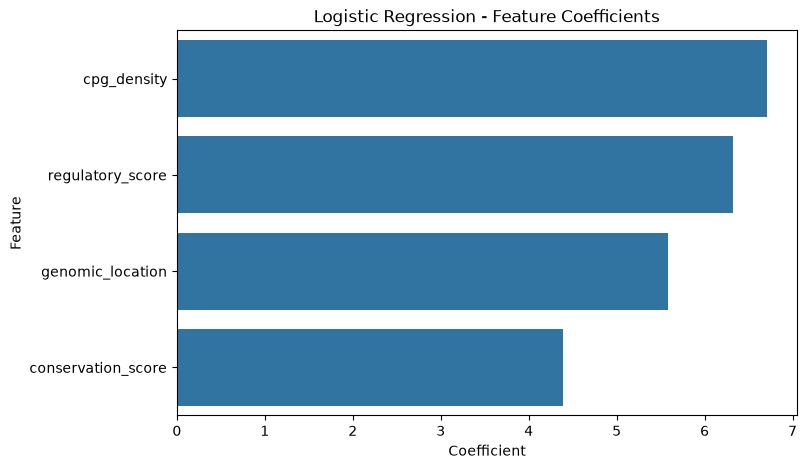

In [63]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=lr_coefficients,
    x='Coefficient',
    y='Feature'
)
plt.title('Logistic Regression - Feature Coefficients')
plt.show()

In [64]:
import joblib

In [65]:
joblib.dump(lr_model, 'dna_methylation_model.pkl')
print("Model saved successfully!")

Model saved successfully!


In [66]:
loaded_model = joblib.load('dna_methylation_model.pkl')
print("Model loaded successfully!")

Model loaded successfully!


In [68]:
loaded_pred = loaded_model.predict(x_test)

In [69]:
print("Original Model Accuracy:",
      accuracy_score(y_test, lr_pred))

print("Loaded Model Accuracy:",
      accuracy_score(y_test, loaded_pred))

print("\nPredictions Match:",
      np.array_equal(lr_pred, loaded_pred))

Original Model Accuracy: 0.975
Loaded Model Accuracy: 0.975

Predictions Match: True


In [70]:
# Check overlap between training and testing datasets
overlap = pd.merge(
    train_data,
    test_data,
    how='inner'
)
print("Overlapping records:", len(overlap))
# Check whether full dataset contains all training records
print("Training records in full dataset:",
      len(pd.merge(train_data, full_data)))
# Check whether full dataset contains all testing records
print("Testing records in full dataset:",
      len(pd.merge(test_data, full_data)))

Overlapping records: 0
Training records in full dataset: 800
Testing records in full dataset: 200


In [71]:
correlation = train_data.corr()

print(
    correlation['methylation_status']
    .sort_values(ascending=False)
)

methylation_status    1.000000
regulatory_score      0.526496
cpg_density           0.409421
genomic_location      0.374652
conservation_score    0.261519
Name: methylation_status, dtype: float64


In [72]:
print("FULL DATASET")
display(full_data.head(10))

print("UNIQUE VALUES")
for column in full_data.columns:
    print(column, ":", full_data[column].nunique())

FULL DATASET


,cpg_density,genomic_location,regulatory_score,conservation_score,methylation_status
0,0.799343,0.949839,0.297447,0.268438,1
1,0.672347,0.831158,0.456644,0.477923,1
2,0.829538,0.614908,0.262274,0.567279,0
3,1.000000,0.438266,0.407612,1.000000,1
4,0.653169,0.774556,0.000000,0.761311,0
5,0.653173,0.698371,0.563988,0.382904,0
6,1.000000,0.823798,0.500362,0.747207,1
7,0.853487,0.758793,0.254873,0.340539,0
8,0.606105,0.862388,0.697774,0.866538,1
9,0.808512,0.466191,0.781271,0.555775,1


UNIQUE VALUES
cpg_density : 926
genomic_location : 923
regulatory_score : 915
conservation_score : 957
methylation_status : 2


In [73]:
full_data[['cpg_density',
           'genomic_location',
           'regulatory_score',
           'conservation_score']].agg(
    ['min', 'max', 'mean', 'std']
)

,cpg_density,genomic_location,regulatory_score,conservation_score
min,0.051747,0.000000,0.000000,0.064110
max,1.000000,1.000000,1.000000,1.000000
mean,0.697508,0.611986,0.501159,0.643147
std,0.183028,0.234104,0.270085,0.198944


In [74]:
full_data.groupby('methylation_status')[
    ['cpg_density',
     'genomic_location',
     'regulatory_score',
     'conservation_score']
].mean()

,cpg_density,genomic_location,regulatory_score,conservation_score
methylation_status,,,,
0,0.614316,0.524761,0.339433,0.584484
1,0.764481,0.682206,0.631357,0.690374


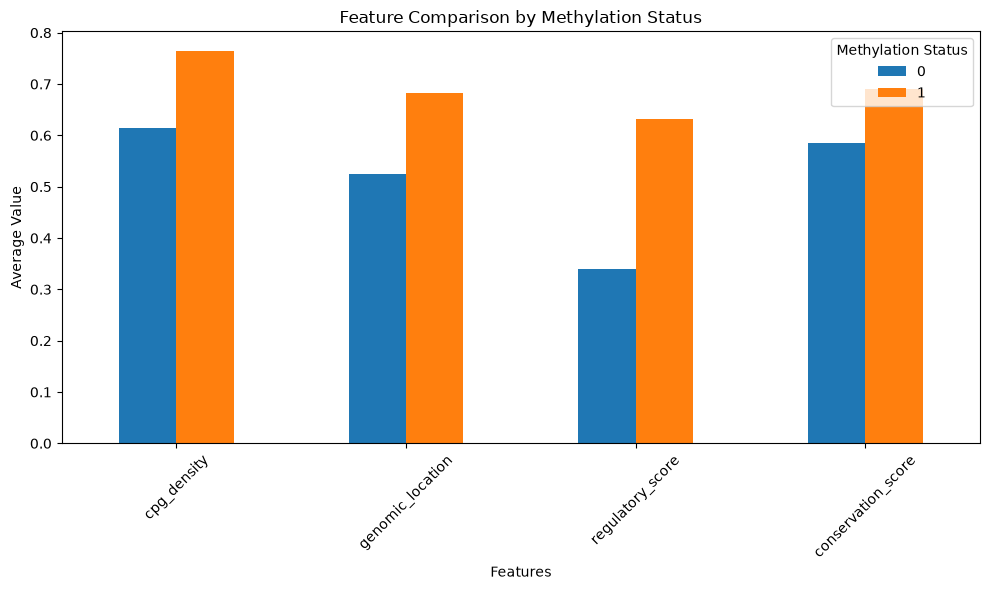

In [75]:
class_comparison = full_data.groupby(
    'methylation_status'
)[
    ['cpg_density',
     'genomic_location',
     'regulatory_score',
     'conservation_score']
].mean()

class_comparison.T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Feature Comparison by Methylation Status')
plt.xlabel('Features')
plt.ylabel('Average Value')
plt.xticks(rotation=45)
plt.legend(title='Methylation Status')
plt.tight_layout()
plt.show()

In [76]:
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': lr_pred
})

results.head(10)

,Actual,Predicted
0,1,1
1,1,1
2,1,1
3,1,1
4,0,0
5,0,0
6,1,1
7,1,1
8,0,0
9,0,0


In [77]:
results['Correct'] = (
    results['Actual'] == results['Predicted']
)

print("Correct Predictions:",
      results['Correct'].sum())

print("Incorrect Predictions:",
      (~results['Correct']).sum())

Correct Predictions: 195
Incorrect Predictions: 5


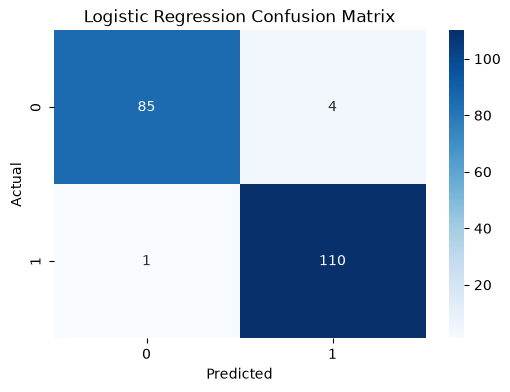

In [78]:
cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.show()

In [79]:
!pip freeze > requirements.txt